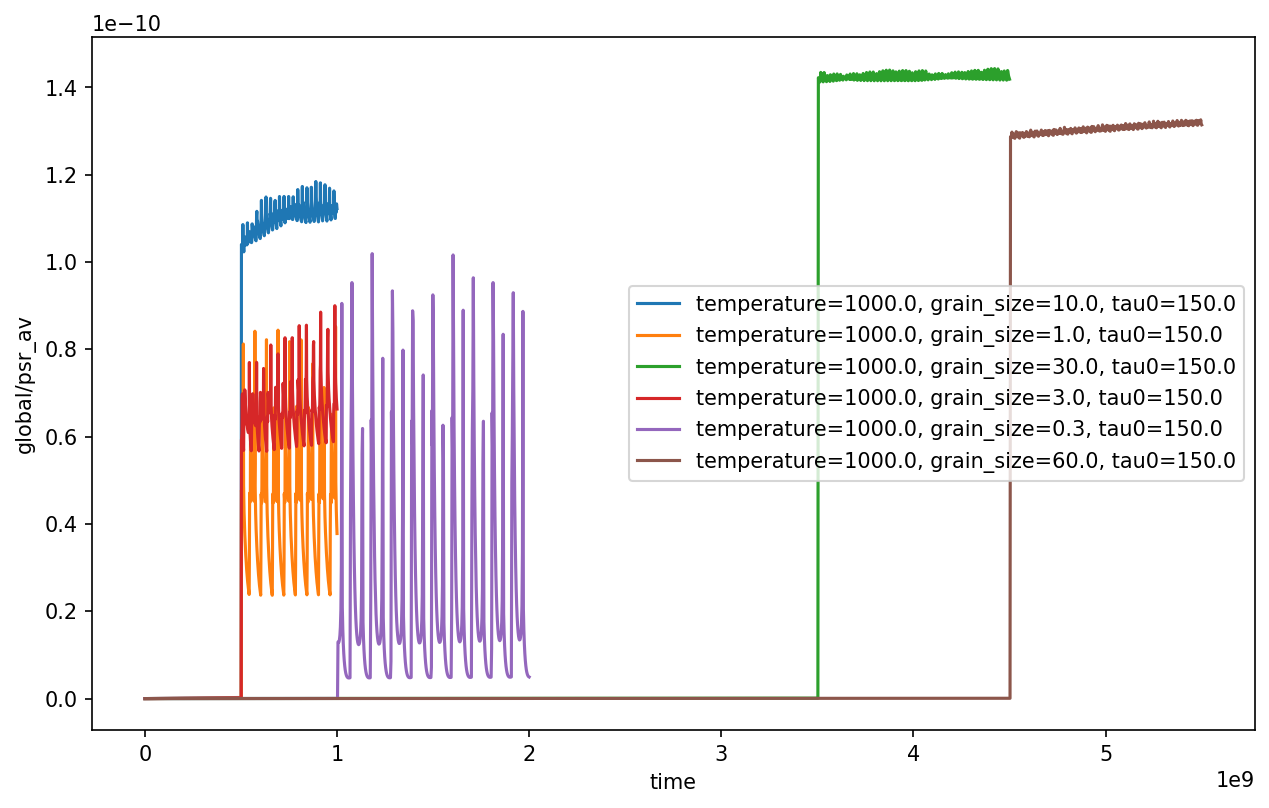

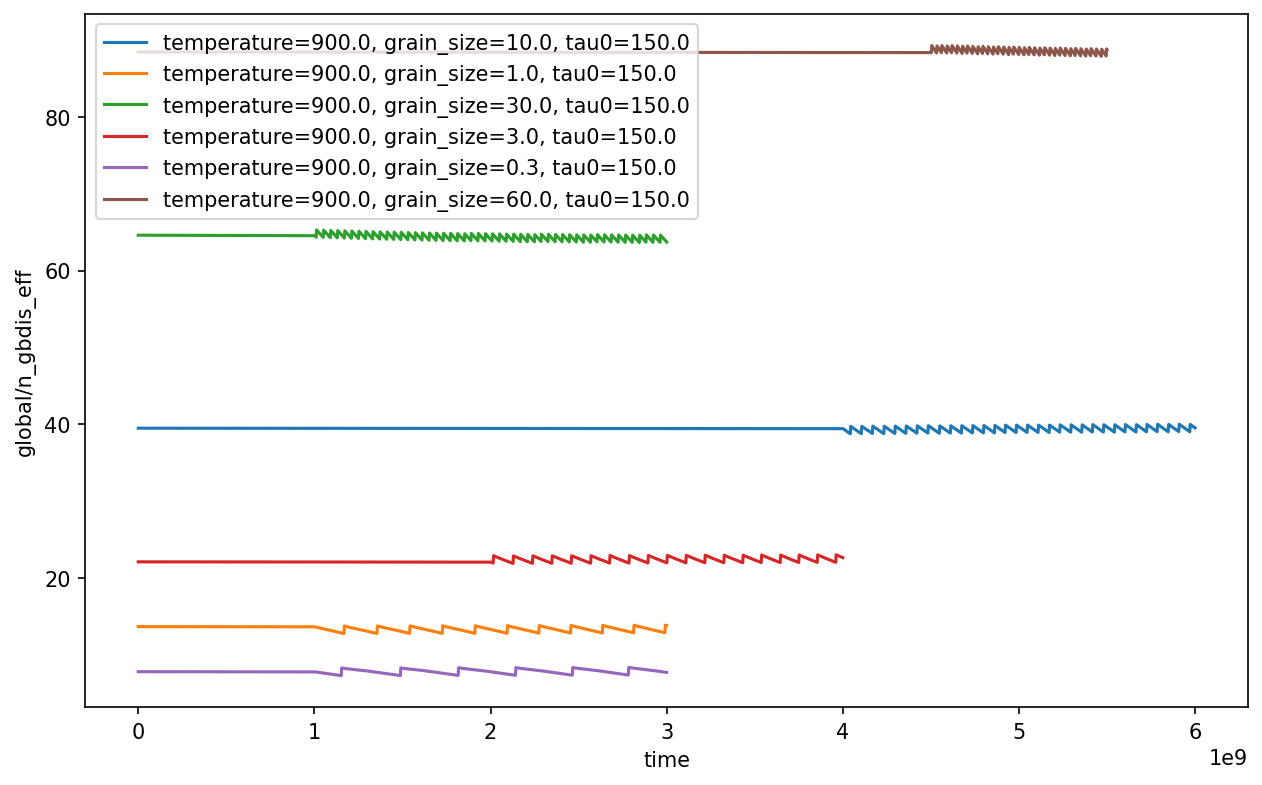

In [5]:
from pylabdd.hdf5_catalog import HDF5Catalog

with HDF5Catalog("/Users/alexander/Codes/pyLabDD/data/hdf5_catalog.sqlite") as catalog:
    runs = catalog.query(
        {"temperature": 900, "tau0": 150},
        dataset="global/psr_av",
    )
    catalog.plot_group("global/psr_av", {"temperature": 1000, "tau0": 150, "length_grain_boundary": 0.1})
    catalog.plot_group("global/n_gbdis_eff", {"temperature": 900, "tau0": 150, "length_grain_boundary": 0.1})

In [ ]:
runs


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pylabdd as dd
from matplotlib.gridspec import GridSpec
from scipy.signal import savgol_filter

def run_iter(
    fill_fact=0.75,
    *,
    tau0=150.0,
    temp=500.0,
    len_gb_seg=0.1,
    grain_size=10.0,
    Ngbn=None,
    maxdis=1000,
    maxout=200,
    niter=20_000_000,
    tfin=0.0,
    dtmax=None,
    screenout=True,
    mu=44.e3,
    nu=0.3,
    B=0.25e-3,
    delta=0.004,
    Qact=95.e3,
    drag=500.,
    Dif_gb=10.,
    time_inc=0.5e9,
    max_iter=9,
    stability_window=100,
    stability_tol=2,
    variation_fraction=0.07,
    plot=True,
    save=True,
    output_prefix="gbpre",
    **gbdd_kwargs,
):
    """Run iterative GBDD simulations until the pile-up is stable.

    Parameters not used directly by this driver are forwarded to
    ``dd.GB_dislocations`` through ``gbdd_kwargs``.
    """
    if Ngbn is None:
        Ngbn = int(len_gb_seg / delta)
        if Ngbn % 2 == 0:
            Ngbn += 1
    if dtmax is None:
        dtmax = 6.25e-7 / delta**4

    gbdd_init = {
        "temp": temp,
        "tau0": tau0,
        "Ngbn": Ngbn,
        "len_gb_seg": len_gb_seg,
        "grain_size": grain_size,
        "maxdis": maxdis,
        "maxout": maxout,
        "niter": niter,
        "dtmax": dtmax,
        "screenout": screenout,
        "mu": mu,
        "nu": nu,
        "B": B,
        "delta": delta,
        "Qact": Qact,
        "drag": drag,
        "Dif_gb": Dif_gb,
    }
    gbdd_init.update(gbdd_kwargs)

    hc = mu * B / (2 * np.pi * (1. - nu))

    def initial_pileup_positions(fill_fact):
        ndis = int(fill_fact * np.pi * (1 - nu) * grain_size * tau0 / (mu * B))
        if ndis < 2:
            raise ValueError(
                f"Initial pile-up has {ndis} dislocations; increase fill_fact, grain_size, or tau0."
            )
        dmax = np.pi**2 * grain_size / (64 * fill_fact * ndis**2)
        ypos = np.zeros(ndis)
        ypos[1] = dmax
        for i in range(2, ndis):
            x0 = ypos[i - 1]
            ypos[i] = x0 + np.pi * hc / (tau0 * np.sqrt((grain_size * fill_fact - x0) / x0))
        return ypos.copy()

    # Set pre-existing dislocations in pile-up
    pudis = initial_pileup_positions(fill_fact)
    Ntot = pudis.size
    vout = None
    r_time = None
    nabs = None
    res_ = []
    it = 1
    ii = 1
    npu_const = False
    while not npu_const and it < max_iter:
        # Run gbdd simulation
        tfin += time_inc
        print(f"### it={it}, ii={ii}, tfin={tfin:.2e}, Ntot={Ntot}")
        gbdd = dd.GB_dislocations(tfin=tfin, **gbdd_init)
        gbdd.run_sim(pudis=pudis, vout=vout, r_time=r_time, nabs=nabs)
        if plot:
            gbdd.plot_time_series(["n_slip_dis", "n_absorbed", "n_gbdis_eff"])
            gbdd.plot_time_series("plast_slip_rate")
        if save:
            fname = (
                f"{output_prefix}_{ii}_{Ntot}_tau{int(tau0)}_T{int(temp)}_"
                f"H{int(grain_size*10)}_L{int(len_gb_seg*10)}.h5"
            )
            gbdd.save_hdf5(fname)
        res_.append(gbdd)

        if gbdd.nout < stability_window:
            raise ValueError(
                "Not enough output data to check pile-up stability. "
                "Increase max_iter or restart from an HDF5 file."
            )
        hh = gbdd.glob_data["n_slip_dis"][gbdd.nout-stability_window:gbdd.nout]
        hmax = max(hh)
        hmin = min(hh)
        hvar = hmax - hmin
        if hvar < stability_tol:
            npu_const = True
            print(f"Pile-up is stable at it={it}, ii={ii}, tfin={tfin:.2e}, Nslip={gbdd.glob_data['n_slip_dis'][-1]}")
        elif hvar > variation_fraction*hmax:
            sample_width = max(1, stability_window // 5)
            h1 = np.mean(gbdd.glob_data["n_slip_dis"][gbdd.nout-stability_window:gbdd.nout-stability_window+sample_width])
            h2 = np.mean(gbdd.glob_data["n_slip_dis"][gbdd.nout-sample_width:gbdd.nout])
            if h2-h1 > 0.:
                # number of slip dislocation increasing, pile-up is still growing, increase initial number of dislocations
                fill_fact *= 1.2
                print(f"Pile-up is growing, re-starting simulation with fill_fact={fill_fact}")
            else:
                # number of slip dislocation decreasing, pile-up is shrinking, decrease initial number of dislocations
                fill_fact *= 0.8
                print(f"Pile-up is shrinking, re-starting simulation with fill_fact={fill_fact}")
            pudis = initial_pileup_positions(fill_fact)
            Ntot = pudis.size
            vout = None
            r_time = None
            nabs = None
            res_ = []
            tfin = 0.
            ii = 0
        else:
            pudis=gbdd.pu_dis['position'][gbdd.nout-1, :].copy()
            vout=gbdd.vout[gbdd.nout-1, :, :].copy()
            r_time=float(gbdd.sim_time[gbdd.nout-1])
            nabs=gbdd.nabs
            print(f"Pile-up is not yet stable at it={it}, ii={ii}, r_time={r_time}, nout={gbdd.nout}, hvar={hvar}")
        it += 1
        ii += 1
    return res_

# plot function for stress and pile-up dislocations
def plot_stress_bfield(dsl, npu, npt = 300, file=None, cutoff=100.):
    xpts = np.linspace(0.0, dsl.lx, npt)
    ypts = np.linspace(0.0, dsl.ly, npt)
    XP, YP = np.meshgrid(xpts, ypts)
    s12 = np.zeros((npt, npt), dtype=np.float64)
    for i in range(dsl.Ntot):
        s12 += dsl.bx[i] * dsl.sig_xy(XP - dsl.xpos[i], YP - dsl.ypos[i])
        s12 -= dsl.by[i] * dsl.sig_xy(YP - dsl.ypos[i], XP - dsl.xpos[i])
    extent = (0.0, dsl.lx, 0.0, dsl.ly)
    
    #fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 12), gridspec_kw={"height_ratios": [4, 1]}, sharex=True)
    fig = plt.figure(figsize=(12, 9))
    gs = GridSpec(2, 1, height_ratios=[4, 1], hspace=0.0)
    # -----------------------------
    # upper plot: stress field and dislocations
    # -----------------------------
    ax1 = fig.add_subplot(gs[0])
    #ax1.xaxis.set_label_position('top')
    #ax1.set_xlabel(r"x ($\mu$m)")
    ax1.xaxis.tick_top()
    plt.setp(ax1.get_xticklabels(), visible=False)
    ax1.set_ylabel(r"y ($\mu$m)")
    im = ax1.imshow(s12, origin="lower", extent=extent,
        vmin=-cutoff, vmax=cutoff, cmap=plt.cm.RdBu, aspect="equal")
    ax1.scatter(dsl.xpos[:npu], dsl.ypos[:npu], s=10, c="yellow", marker="o")
    cbar = fig.colorbar(im, ax=ax1, pad=0.08)
    #cbar.set_label(r"$\sigma_{12}$ (MPa)")
    cbar.ax.set_title(r"$\sigma_{12}$ (MPa)")
    
    # -----------------------------
    # Lower Plot: b-field
    # -----------------------------
    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    ax2.plot(dsl.xpos[npu:], dsl.by[npu:], lw=2)  #color=plt.cm.viridis(0)
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_ylim(0., dsl.by[npu:].max())
    ax2.invert_yaxis()
    pos1 = ax1.get_position()
    pos2 = ax2.get_position()
    ax2.set_position([
        pos1.x0,
        pos2.y0,
        pos1.width,
        pos2.height
    ])
    ax2.set_ylabel(r"$b_y \, / \, B$")
    ax2.set_xlabel(r"x ($\mu$m)")
    ax2.yaxis.set_label_position('right')
    ax2.yaxis.tick_right()
    if file is not None:
        plt.savefig(file, dpi=300)
    plt.show()

In [ ]:
# set material parameters
b0 = 0.25e-3
nu = 0.3
mu = 44.e3
drag = 500.
Qact = 95.e3
Dif_gb = 10.
hc = mu*b0/(2*np.pi*(1.-nu))   # Constant for dislocation stress field

# set simulation parameters
temp = 900.0
tau0 = 150.0
gs = 10.0
lgb = 0.1
delta = 0.004
ngbn = int(lgb/delta)
if ngbn % 2 == 0: ngbn += 1
dtmax = 6.25e-7/delta**4  # value 1.e4 for delta=0.005, 50. for PU
time_inc = 0.5e9
niter = 20_000_000
maxout = 200

D2_list = [0.3, 1.0, 3.0, 10.0, 30.0]

In [ ]:
for i, gs in enumerate(D2_list):
    print(f"=====  Simulation with N_gbn={ngbn}, grain_size={gs}, dtmax={dtmax}")  
    res_ = run_iter(
        fill_fact=0.75,
        temp=temp, tau0=tau0,
        Ngbn=ngbn, len_gb_seg=lgb, grain_size=gs,
        time_inc=time_inc, niter=niter, maxout=maxout,
        dtmax=dtmax, drag=drag,
        nu=nu, mu=mu, B=b0,
        Qact=Qact, Dif_gb=Dif_gb,
        screenout=True,
        plot=True,
        save=False,
        )
    gbo = res_[-1]
    gbo.save_hdf5(f"gb_final_tau{int(tau0)}_T{int(temp)}_"
                f"H{int(gs*10)}_L{int(lgb*10)}.h5", overwrite=True)

In [ ]:
len(res_)

In [ ]:
plt.rcParams["font.size"] = 20

fig, ax = plt.subplots(figsize=(12, 8), dpi=200)
for i in range(Np):
    plt.plot(sim_time[i, :nit[i]-20]*1.e-6,
             psr_av[i, :nit[i]-20]*1.e9,
             marker="none",
             linestyle="-",
             color=plt.cm.viridis(i / max(1, Np)),
             label=f"D={gs_list[i]}"+r" $\mu$m"
             )
plt.legend(loc="upper right", bbox_to_anchor=(1.3, 1.02))
plt.xlabel(r"$t$ (s)")
plt.ylabel(r"$\dot\gamma_{pl}$ (10$^{-3}$/s)")
#plt.savefig('pu1_conv_gd_ngbn_semilog.pdf', dpi=300, format='pdf')
plt.show()

fig, ax = plt.subplots(figsize=(12, 8), dpi=200)
#xval = 1./np.sqrt(gs_list)
#xlabel = r"$1/\sqrt{H}$ ($\mu$m$^{-1/2}$)"
xval = gs_list
xlabel = r"$H$ ($\mu$m)"
plt.plot(xval, psr_list[0,:]*1.e9,
         color='red',
        label=f"T=900 K")
plt.plot(xval, psr_list[1,:]*1.e9,
         color='orange',
        label=f"T=700 K")
plt.plot(xval, psr_list[2,:]*1.e9,
         color='blue',
        label=f"T=500 K")
plt.xlabel(xlabel)
plt.ylabel(r"$\dot\gamma_{pl}$ (10$^{-3}$/s)")
plt.legend()
plt.show()

In [ ]:
psr0 = np.array([[ 1.33603495e-10,  2.00375364e-10,  2.47692749e-10,
         2.48731915e-10,  2.23303212e-10,  1.11401307e-10],
       [ 2.35187569e-11,  4.04464519e-11,  6.37819978e-11,
         1.30645999e-10,  1.94046861e-10,  0.00000000e+00],
       [-9.34075694e-13,  2.97644063e-14,  2.78368262e-13,
         5.12428036e-11,  1.66057001e-10,  0.00000000e+00]])
err = psr_list/psr0[:, :4] - 1.
print(err)

In [ ]:
gbdd.plot_pile_up()
gbdd.plot_time_series('n_slip_dis')

In [ ]:
it = 500
plt.rcParams["font.size"] = 12
sp_ang = 0.5*np.pi
C = gbdd.mu*gbdd.B/(2*np.pi*(1.-gbdd.nu))   # Constant for dislocation stress field
hh = gbdd.pu_dis['position'][it, :]
ind = np.nonzero(hh)[0]
npu = len(ind)
assert npu == gbdd.glob_data['n_slip_dis'][it]
ngbn = gbdd.Ngbn
Nc = int((ngbn+1)/2) - 1
gbdx = gbdd.Dgp/(ngbn-1)
ndis = npu + ngbn
xp = np.zeros(ndis)
yp = np.zeros(ndis)
by = np.ones(ndis)
yp[0:npu] = hh[ind]  # positions of pile-up dislocations stored in first section of array, GB is at y=0
xp[0:npu] = np.ones(npu)*gbdd.Dgp*0.5  # x-positions of pile-up dislocations
xp[npu:] = gbdd.gb_node_pos + gbdd.Dgp*0.5
by[npu:] = gbdd.field_data['bfield'][it, :]  #np.zeros(ngbn) #
print(f"Number of dislocations: {npu}, Simulation time: {gbdd.sim_time[it]*1.e-6}")

#define different dislocations in box
# initialze object of class Dislocations
dsl = dd.Dislocations(ndis, npu, sp_ang, C, gbdd.B,
                      xpos=xp, ypos=yp, LX=gbdd.Dgp, LY=gbdd.D2,  #LX=50000, LY=50000, #
                      bc="fixed")
dsl.by = by
plot_stress_bfield(
    dsl, npu,
    file=f"sigpu_tau{int(gbdd.tau0)}_T{int(gbdd.temp)}_D{int(gbdd.D2*10)}_L{int(gbdd.Dgp*10)}.pdf", 
    cutoff=200
    )
